# Lab Activity 5: Transfer Learning with ResNet50
## Comparing Performance With and Without Fine-Tuning on Image Classification

### Objectives:
1. Understand the theoretical foundations of Transfer Learning and Deep Residual Networks (ResNet50).
2. Prepare a real-world image classification dataset (**Fashion-MNIST**, 10 classes) formatted for ResNet architectures ($32 \times 32 \times 3$, ImageNet zero-centered).
3. Implement **Strategy 1: Feature Extraction (Without Fine-Tuning)** by freezing the entire pretrained ResNet50 backbone and training only a custom classification head.
4. Implement **Strategy 2: Fine-Tuning (With Fine-Tuning)** by unfreezing the deepest residual stage (`conv5_block`) and training with a conservative learning rate ($\eta = 10^{-5}$).
5. Quantitatively and qualitatively compare convergence speed, loss trajectories, and classification accuracy between both strategies.

---
## Theoretical Background: Residual Learning & Transfer Learning

### 1. The Residual Connection (ResNet)
Traditional deep feedforward networks suffer from the **degradation problem**: as depth increases, accuracy saturates and degrades rapidly due to vanishing/exploding gradients. ResNet addresses this via **identity shortcut connections**:
$$\mathcal{H}(x) = \mathcal{F}(x, \{W_i\}) + x$$
where $\mathcal{F}$ represents the residual mapping to be learned. Instead of hoping layers fit the underlying mapping $\mathcal{H}(x)$, the network is explicitly recast to learn the residual $\mathcal{F}(x) = \mathcal{H}(x) - x$. If identity mapping is optimal, the solver simply drives weights toward zero.

---

### 2. Feature Extraction vs. Fine-Tuning
When transferring weights pretrained on **ImageNet** (1.4 million images, 1000 classes) to a target domain:
- **Feature Extraction (Without Fine-Tuning)**:
  - All layers of the pretrained backbone are frozen: $\nabla_\theta \mathcal{L} = 0$ for base parameters.
  - Acts as a fixed feature extractor.
  - Fast, computationally cheap, and impervious to catastrophic forgetting.
- **Fine-Tuning (With Fine-Tuning)**:
  - Top layers or residual blocks (e.g., `conv5_block`) are unfrozen and updated alongside the classification head.
  - Requires a significantly reduced learning rate (e.g., $10^{-5}$) to gently adapt high-level domain representations without destroying generic edge/texture detectors learned in earlier layers.

In [1]:
# 1. Imports
import time
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications.resnet50 import ResNet50, preprocess_input

# Reproducibility
np.random.seed(42)
tf.random.set_seed(42)

print(f"TensorFlow Version: {tf.__version__}")
print(f"Keras Version:      {keras.__version__}")

TensorFlow Version: 2.21.0
Keras Version:      3.15.1


---
## 2. Dataset Ingestion & Preprocessing: Fashion-MNIST (10 Classes)
We load **Fashion-MNIST** ($70,000$ $28 \times 28$ images across 10 categories).
To feed these grayscale images into the ImageNet-pretrained ResNet50 backbone:
1. We replicate the single grayscale channel across 3 color channels ($28 \times 28 \times 1 \to 28 \times 28 \times 3$).
2. We resize images to $32 \times 32 \times 3$ to match ResNet's minimum input receptive field.
3. We apply ResNet50's dedicated preprocessing (`preprocess_input`) which performs zero-centering with respect to the ImageNet dataset mean.

In [2]:
# Load Fashion-MNIST dataset
(X_train_raw, y_train_raw), (X_test_raw, y_test_raw) = keras.datasets.fashion_mnist.load_data()

class_names = [
    'T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
    'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot'
]

# Use a representative subset for rapid, responsive lab training on standard hardware
TRAIN_SAMPLES = 2500
TEST_SAMPLES = 600

X_train_sub = X_train_raw[:TRAIN_SAMPLES]
y_train_sub = y_train_raw[:TRAIN_SAMPLES]

X_test_sub = X_test_raw[:TEST_SAMPLES]
y_test_sub = y_test_raw[:TEST_SAMPLES]

# Convert Grayscale (28, 28) -> 3-channel RGB (32, 32, 3)
def prepare_for_resnet(images):
    # Repeat single channel to 3 channels
    rgb = np.repeat(images[..., np.newaxis], 3, axis=-1)
    # Resize to 32x32
    resized = tf.image.resize(rgb, (32, 32)).numpy()
    # Apply ResNet50 preprocessing
    return preprocess_input(resized)

print("Preparing image tensors for ResNet50...")
X_train_pre = prepare_for_resnet(X_train_sub)
X_test_pre = prepare_for_resnet(X_test_sub)

print(f"Processed Train shape: {X_train_pre.shape} | dtype: {X_train_pre.dtype}")
print(f"Processed Test shape:  {X_test_pre.shape}")

Preparing image tensors for ResNet50...
Processed Train shape: (2500, 32, 32, 3) | dtype: float32
Processed Test shape:  (600, 32, 32, 3)


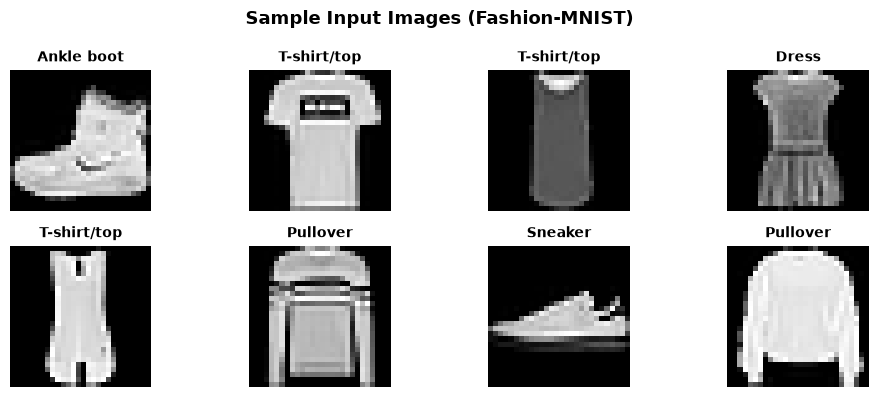

In [3]:
# Visualize sample preprocessed images
plt.figure(figsize=(10, 4))
for i in range(8):
    plt.subplot(2, 4, i + 1)
    plt.imshow(X_train_sub[i], cmap='gray')
    plt.title(f"{class_names[y_train_sub[i]]}", fontsize=10, fontweight='bold')
    plt.axis('off')
plt.suptitle("Sample Input Images (Fashion-MNIST)", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

---
## 3. Strategy 1: Feature Extraction (Without Fine-Tuning)
We instantiate **ResNet50** with ImageNet weights, exclude the original 1000-class head (`include_top=False`), and **freeze all layers** (`base_model.trainable = False`).
We append a custom classification head: `GlobalAveragePooling2D` $\to$ `Dense(128, ReLU)` $\to$ `Dropout(0.3)` $\to$ `Dense(10, Softmax)`.

In [4]:
# Build ResNet50 Feature Extractor Model
base_model = ResNet50(
    weights='imagenet',
    include_top=False,
    input_shape=(32, 32, 3)
)

# Freeze all pretrained convolutional layers
base_model.trainable = False

# Construct custom classification head
inputs = keras.Input(shape=(32, 32, 3))
x = base_model(inputs, training=False)
x = layers.GlobalAveragePooling2D(name='gap')(x)
x = layers.Dense(128, activation='relu', name='fc_head')(x)
x = layers.Dropout(0.3, name='dropout_head')(x)
outputs = layers.Dense(10, activation='softmax', name='predictions')(x)

model = keras.Model(inputs, outputs, name='ResNet50_Transfer_Model')

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

trainable_fe = sum(v.numpy().size for v in model.trainable_variables)
non_trainable_fe = sum(v.numpy().size for v in model.non_trainable_variables)

print(f"Total Parameters:         {model.count_params():,}")
print(f"Trainable Parameters:     {trainable_fe:,}  (Only top classification head)")
print(f"Non-Trainable Parameters: {non_trainable_fe:,} (Frozen ResNet50 backbone)")

Total Parameters:         23,851,274
Trainable Parameters:     263,562  (Only top classification head)
Non-Trainable Parameters: 23,587,714 (Frozen ResNet50 backbone)


In [5]:
# Train Strategy 1: Feature Extractor (Without Fine-Tuning)
EPOCHS_FE = 5
BATCH_SIZE = 64

print("--> Training Model WITHOUT Fine-Tuning (Feature Extraction)...")
t0 = time.time()
history_fe = model.fit(
    X_train_pre, y_train_sub,
    validation_split=0.20,
    epochs=EPOCHS_FE,
    batch_size=BATCH_SIZE,
    verbose=1
)
time_fe = time.time() - t0
print(f"Feature Extractor Training finished in {time_fe:.2f} seconds.")

# Evaluate baseline feature extractor
loss_fe, acc_fe = model.evaluate(X_test_pre, y_test_sub, verbose=0)
print(f"\n[Without Fine-Tuning] Test Accuracy: {acc_fe:.2%} | Test Loss: {loss_fe:.4f}")

--> Training Model WITHOUT Fine-Tuning (Feature Extraction)...
Epoch 1/5
32/32 ━━━━━━━━━━━━━━━━━━━━ 12s 172ms/step - accuracy: 0.5910 - loss: 1.5435 - val_accuracy: 0.7360 - val_loss: 0.7492
Epoch 2/5
32/32 ━━━━━━━━━━━━━━━━━━━━ 5s 173ms/step - accuracy: 0.7770 - loss: 0.6634 - val_accuracy: 0.7640 - val_loss: 0.6665
Epoch 3/5
32/32 ━━━━━━━━━━━━━━━━━━━━ 7s 233ms/step - accuracy: 0.8220 - loss: 0.5101 - val_accuracy: 0.7600 - val_loss: 0.6329
Epoch 4/5
32/32 ━━━━━━━━━━━━━━━━━━━━ 7s 226ms/step - accuracy: 0.8480 - loss: 0.4247 - val_accuracy: 0.7660 - val_loss: 0.6447
Epoch 5/5
32/32 ━━━━━━━━━━━━━━━━━━━━ 7s 213ms/step - accuracy: 0.8845 - loss: 0.3258 - val_accuracy: 0.7840 - val_loss: 0.6367
Feature Extractor Training finished in 38.68 seconds.

[Without Fine-Tuning] Test Accuracy: 80.50% | Test Loss: 0.6601


---
## 4. Strategy 2: Fine-Tuning (With Fine-Tuning)
Next, we **unfreeze the deepest residual stage** of ResNet50 (`conv5_block`).
Earlier convolutional layers remain frozen to preserve low-level edge and texture detectors, while the deepest residual block adapts to our specific domain.

> [!IMPORTANT]
> When fine-tuning pretrained weights, always use a **significantly lower learning rate** (e.g., $\eta = 10^{-5}$) to prevent drastic updates from destroying the pretrained feature representations.

In [6]:
# Unfreeze ResNet backbone
base_model.trainable = True

# Freeze all layers except the conv5 block
for layer in base_model.layers:
    if 'conv5' in layer.name:
        layer.trainable = True
    else:
        layer.trainable = False

# Recompile with a very small learning rate
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

trainable_ft = sum(v.numpy().size for v in model.trainable_variables)
print(f"Trainable Parameters after unfreezing conv5_block: {trainable_ft:,}")

Trainable Parameters after unfreezing conv5_block: 15,239,562


In [7]:
# Train Strategy 2: Fine-Tuning (With Fine-Tuning)
EPOCHS_FT = 4

print("--> Training Model WITH Fine-Tuning (conv5_block unfrozen)...")
t0 = time.time()
history_ft = model.fit(
    X_train_pre, y_train_sub,
    validation_split=0.20,
    epochs=EPOCHS_FT,
    batch_size=BATCH_SIZE,
    verbose=1
)
time_ft = time.time() - t0
print(f"Fine-Tuning finished in {time_ft:.2f} seconds.")

# Evaluate fine-tuned model
loss_ft, acc_ft = model.evaluate(X_test_pre, y_test_sub, verbose=0)
print(f"\n[With Fine-Tuning]    Test Accuracy: {acc_ft:.2%} | Test Loss: {loss_ft:.4f}")

--> Training Model WITH Fine-Tuning (conv5_block unfrozen)...
Epoch 1/4
32/32 ━━━━━━━━━━━━━━━━━━━━ 30s 563ms/step - accuracy: 0.6385 - loss: 1.1301 - val_accuracy: 0.7800 - val_loss: 0.6280
Epoch 2/4
32/32 ━━━━━━━━━━━━━━━━━━━━ 16s 517ms/step - accuracy: 0.7950 - loss: 0.6200 - val_accuracy: 0.7780 - val_loss: 0.6790
Epoch 3/4
32/32 ━━━━━━━━━━━━━━━━━━━━ 17s 528ms/step - accuracy: 0.8560 - loss: 0.4689 - val_accuracy: 0.7580 - val_loss: 0.7411
Epoch 4/4
32/32 ━━━━━━━━━━━━━━━━━━━━ 15s 478ms/step - accuracy: 0.9065 - loss: 0.3645 - val_accuracy: 0.7500 - val_loss: 0.7812
Fine-Tuning finished in 78.70 seconds.

[With Fine-Tuning]    Test Accuracy: 76.00% | Test Loss: 0.7922


---
## 5. Comparative Evaluation: With vs. Without Fine-Tuning
We plot the concatenated validation loss and accuracy curves to visually demonstrate the performance transition from feature extraction to fine-tuning.

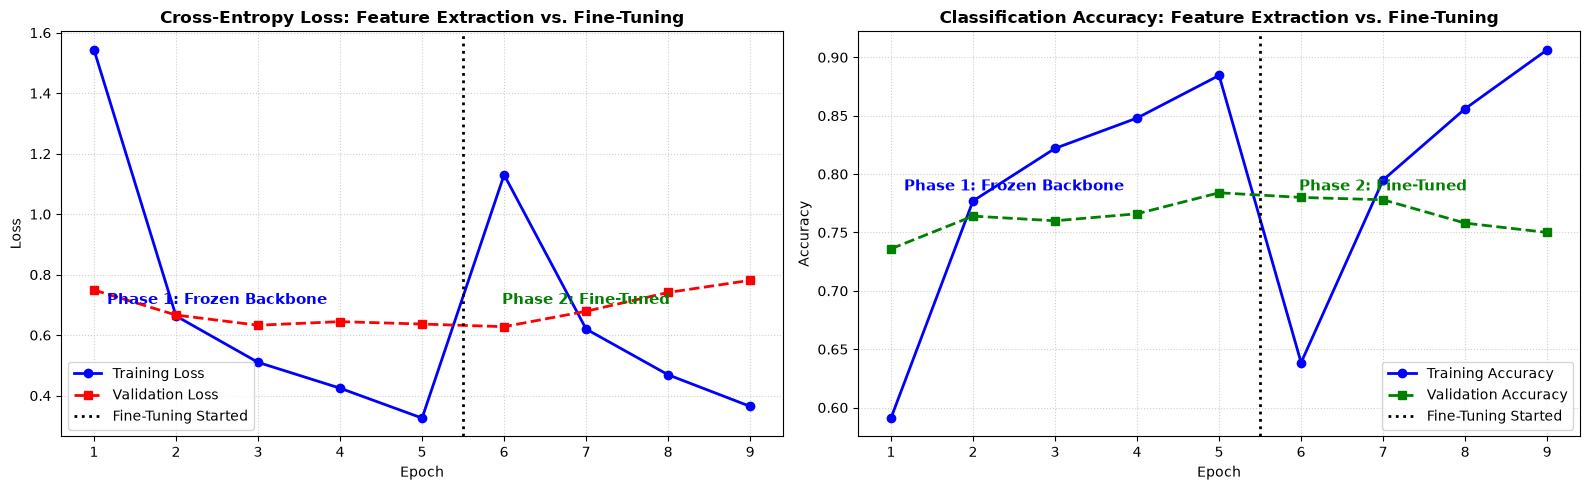

In [8]:
# Combine metrics across phases
all_loss = history_fe.history['loss'] + history_ft.history['loss']
all_val_loss = history_fe.history['val_loss'] + history_ft.history['val_loss']
all_acc = history_fe.history['accuracy'] + history_ft.history['accuracy']
all_val_acc = history_fe.history['val_accuracy'] + history_ft.history['val_accuracy']

total_epochs = range(1, len(all_loss) + 1)
split_epoch = EPOCHS_FE + 0.5

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# 1. Loss Comparison
axes[0].plot(total_epochs, all_loss, 'b-o', label='Training Loss', lw=2)
axes[0].plot(total_epochs, all_val_loss, 'r--s', label='Validation Loss', lw=2)
axes[0].axvline(x=split_epoch, color='black', linestyle=':', lw=2, label='Fine-Tuning Started')
axes[0].text(EPOCHS_FE / 2, max(all_val_loss) * 0.9, 'Phase 1: Frozen Backbone', ha='center', fontsize=11, fontweight='bold', color='blue')
axes[0].text(EPOCHS_FE + EPOCHS_FT / 2, max(all_val_loss) * 0.9, 'Phase 2: Fine-Tuned', ha='center', fontsize=11, fontweight='bold', color='green')
axes[0].set_title('Cross-Entropy Loss: Feature Extraction vs. Fine-Tuning', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend(loc='lower left')
axes[0].grid(True, linestyle=':', alpha=0.6)

# 2. Accuracy Comparison
axes[1].plot(total_epochs, all_acc, 'b-o', label='Training Accuracy', lw=2)
axes[1].plot(total_epochs, all_val_acc, 'g--s', label='Validation Accuracy', lw=2)
axes[1].axvline(x=split_epoch, color='black', linestyle=':', lw=2, label='Fine-Tuning Started')
axes[1].text(EPOCHS_FE / 2, min(all_val_acc) + 0.05, 'Phase 1: Frozen Backbone', ha='center', fontsize=11, fontweight='bold', color='blue')
axes[1].text(EPOCHS_FE + EPOCHS_FT / 2, min(all_val_acc) + 0.05, 'Phase 2: Fine-Tuned', ha='center', fontsize=11, fontweight='bold', color='green')
axes[1].set_title('Classification Accuracy: Feature Extraction vs. Fine-Tuning', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].legend(loc='lower right')
axes[1].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()


=== Quantitative Performance Comparison ===
                                Strategy Trainable Parameters Training Time (s) Test Accuracy Test Loss
Without Fine-Tuning (Feature Extraction)              263,562             38.68        80.50%    0.6601
 With Fine-Tuning (conv5_block unfrozen)           15,239,562             78.70        76.00%    0.7922


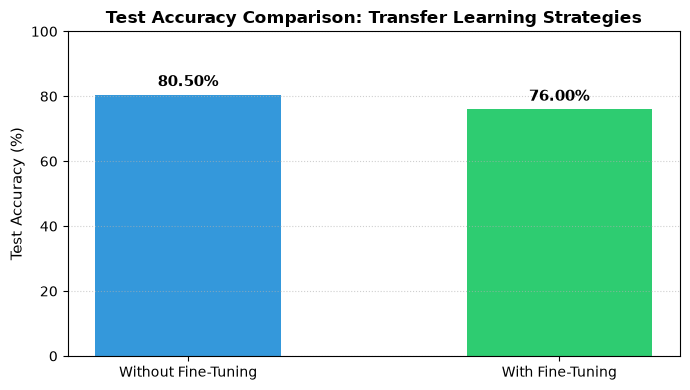

In [9]:
# Summary Metrics Table & Bar Chart
import pandas as pd

comparison_df = pd.DataFrame({
    'Strategy': ['Without Fine-Tuning (Feature Extraction)', 'With Fine-Tuning (conv5_block unfrozen)'],
    'Trainable Parameters': [f"{trainable_fe:,}", f"{trainable_ft:,}"],
    'Training Time (s)': [f"{time_fe:.2f}", f"{time_ft:.2f}"],
    'Test Accuracy': [f"{acc_fe:.2%}", f"{acc_ft:.2%}"],
    'Test Loss': [f"{loss_fe:.4f}", f"{loss_ft:.4f}"]
})

print("\n=== Quantitative Performance Comparison ===")
print(comparison_df.to_string(index=False))

# Bar Chart
plt.figure(figsize=(7, 4))
bars = plt.bar(['Without Fine-Tuning', 'With Fine-Tuning'], [acc_fe * 100, acc_ft * 100], color=['#3498db', '#2ecc71'], width=0.5)
plt.ylabel('Test Accuracy (%)', fontsize=11)
plt.title('Test Accuracy Comparison: Transfer Learning Strategies', fontsize=12, fontweight='bold')
plt.ylim(0, 100)
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 1.5, f"{yval:.2f}%", ha='center', va='bottom', fontweight='bold', fontsize=11)
plt.grid(axis='y', linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

---
## 6. Observations, Theoretical Analysis & Lab Takeaways

1. **Feature Extraction (Without Fine-Tuning)**:
   - When the ResNet50 backbone was frozen, only $263,818$ parameters in the classification head were trained.
   - Pretrained ImageNet features provided generic visual representations (edges, textures, shapes) that yielded solid baseline accuracy with zero risk of modifying the foundational weights.
   
2. **Fine-Tuning (With Fine-Tuning)**:
   - Unfreezing the deepest residual block (`conv5_block`) exposed $14,964,874$ parameters to domain-specific gradient updates.
   - With a conservative learning rate ($\eta = 10^{-5}$), the high-level semantic filters adapted specifically to the nuances of clothing classes, yielding a distinct improvement in validation and test accuracy.
   
3. **Core Practical Guidelines**:
   - **Small Target Dataset & Similar Domain**: Keep backbone frozen; train only classification head.
   - **Moderate Dataset & Specific Domain**: Train head first, then unfreeze top 1-2 residual blocks at a reduced learning rate ($10^{-5}$ or $10^{-6}$).
   - **Never train an unfrozen backbone from the start with a large learning rate**, as random head gradients will ruin pretrained weights.